# 02 · EDA y limpieza

**Hotel Booking Demand · Machine Learning · MUCSI 2026/27 · Universidad de Deusto**

> **TL;DR**
>
> | Pregunta | Decisión | Por qué |
> |---|---|---|
> | ¿Qué falta? | Casi nada. `NULL` en `agent`/`company` = «sin agencia/empresa» | Lo dice el paper: no es un dato perdido |
> | ¿Duplicados? | **Se conservan** y se agrupan con `dup_group_id` | Borrarlos cambia la tasa de cancelación del 37 % al 27,5 % |
> | ¿Filas imposibles? | **182 a cuarentena** | `adr` negativo, `adr` de 5 400 o sin huéspedes |
> | ¿Regresión? | Sin reservas de 0 noches ni `adr` = 0 | Sin noches o sin precio no hay «precio por noche» que predecir |
> | ¿Se aprende algo aquí? | **No** | Medianas, umbrales y escalado se aprenden en el 03 solo con *train* |
>
> **Entra:** `hotels.csv` + los dos JSON del 01 · **Sale:** `data/interim/hotels_clean.csv`

## 0 · Preparar el entorno y leer el 01

In [1]:
import hashlib
import json
import platform
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 42
np.random.seed(SEED)
pd.set_option("display.max_columns", None)

# Project root = the folder that contains requirements.txt (works from notebooks/ or from the root)
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "requirements.txt").exists())
RAW_PATH = ROOT / "data" / "raw" / "hotels.csv"
IN_DIR = ROOT / "outputs" / "01-data-collection-and-quality"
OUT_DIR = ROOT / "outputs" / "02-eda-and-cleaning"
CLEAN_PATH = ROOT / "data" / "interim" / "hotels_clean.csv"
OUT_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_PATH.parent.mkdir(parents=True, exist_ok=True)


def check(condition, ok, fail):
    """Print ✅ if the condition holds and ⚠️ otherwise."""
    print(f"✅ {ok}" if bool(condition) else f"⚠️ {fail}")
    return bool(condition)


def pct(mask):
    """Share of True values, in %."""
    return round(float(np.mean(mask)) * 100, 1)


def sha256_file(path):
    """File fingerprint: if a single byte changes, the hash changes."""
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()

In [2]:
contract = json.loads((IN_DIR / "data_contract.json").read_text(encoding="utf-8"))
summary_01 = json.loads((IN_DIR / "quality_summary.json").read_text(encoding="utf-8"))

check(summary_01["decision"] != "QUARANTINE", f"Notebook 01 says {summary_01['decision']} → we can continue.",
      "Notebook 01 quarantined the batch: stop here.")
check(sha256_file(RAW_PATH) == contract["identity"]["sha256"], "Same file validated in 01.",
      "The file changed after notebook 01: run 01 again.")

SCHEMA = contract["schema"]
FORBIDDEN = contract["purpose"]["forbidden_features"]
UNDER_REVIEW = contract["purpose"]["features_under_review"]
ADR_MAX = SCHEMA["adr"]["max"]
pd.Series(summary_01["pending_decisions_for_02"], name="pending from 01").to_frame()

✅ Notebook 01 says CONTINUE_WITH_CONDITIONS → we can continue.
✅ Same file validated in 01.


,pending from 01
0,"exact duplicates: drop, group within the split..."
1,adr = 0 with nights > 0 (mostly Complementary)...
2,CN versus CHN: unify or not (compare both popu...
3,sentinels: NULL in agent/company = 'none'; NUL...


**Carga.** `raw` se lee como texto y no se toca. `to_typed` aplica las mismas reglas fijas que el 01
(texto → número, fecha de llegada, noches y huéspedes totales).

In [3]:
raw = pd.read_csv(RAW_PATH, dtype=str, keep_default_na=False)
raw.insert(0, "row_id", np.arange(len(raw)))  # technical identifier: position in the file

RAW_COLUMNS = list(raw.columns)
DATA_COLUMNS = RAW_COLUMNS[1:]  # everything except row_id
NUMERIC = ["row_id", "arrival_date_year", "arrival_date_week_number", "arrival_date_day_of_month"] + [
    c for c, s in SCHEMA.items() if s["type"] in {"binary", "count", "count_days", "continuous"}]


def to_typed(frame):
    """Fixed rules (no statistic is learned from the data)."""
    out = frame.astype(str)
    out[NUMERIC] = out[NUMERIC].apply(pd.to_numeric, errors="coerce")
    out["arrival_date"] = pd.to_datetime(
        out["arrival_date_year"].astype(str) + "-" + frame["arrival_date_month"] + "-"
        + out["arrival_date_day_of_month"].astype(str), format="%Y-%B-%d")
    out["total_nights"] = out["stays_in_weekend_nights"] + out["stays_in_week_nights"]
    out["total_guests"] = out["adults"] + out["children"].fillna(0) + out["babies"]
    return out


df = to_typed(raw)
print("Rows:", len(df))

Rows: 119390


## 1 · ¿Cómo son los datos?

Cuatro preguntas, una gráfica cada una. El histograma de `adr` se **dibuja** entre 0 y 300 € para que el
valor de 5 400 no aplaste la forma (dibujar no es filtrar).

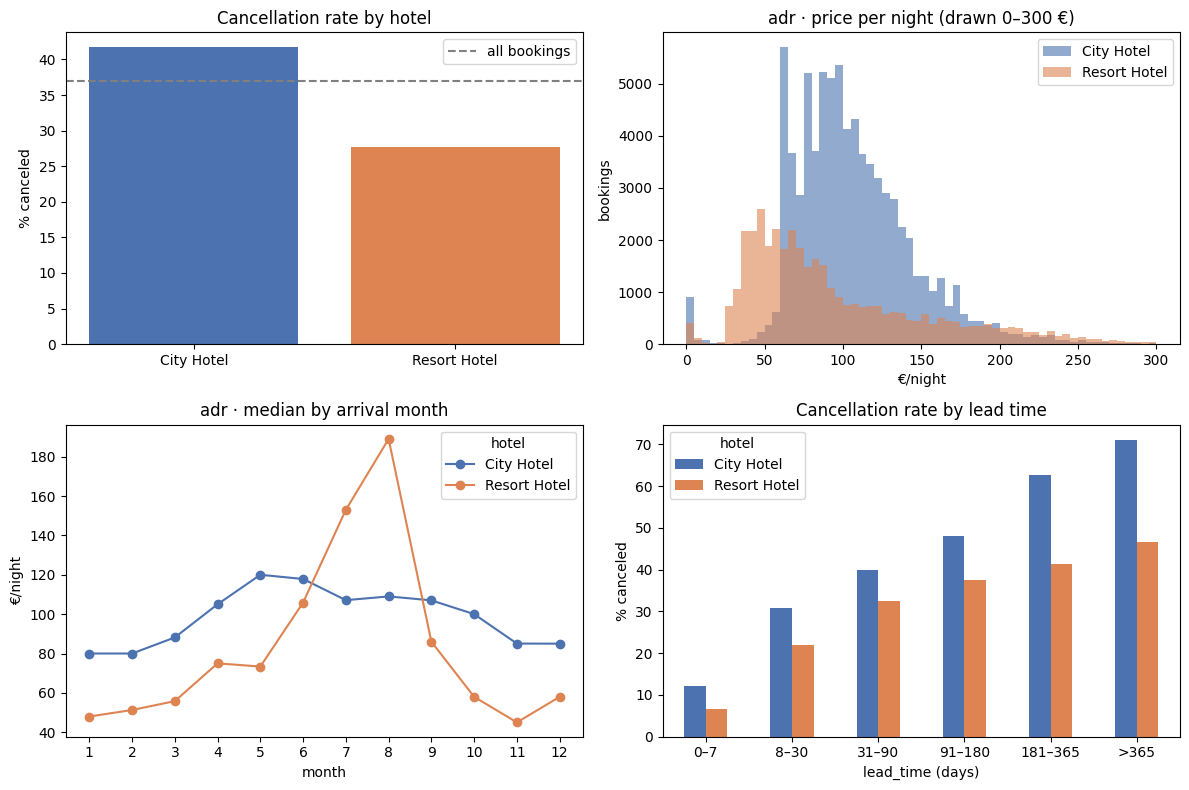

In [4]:
priced = df["total_nights"].gt(0) & df["adr"].between(0, ADR_MAX)  # only for drawing adr
COLORS = {"City Hotel": "#4C72B0", "Resort Hotel": "#DD8452"}
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 1) How much is canceled per hotel?
rates = df.groupby("hotel")["is_canceled"].mean() * 100
axes[0, 0].bar(rates.index, rates.values, color=list(COLORS.values()))
axes[0, 0].axhline(df["is_canceled"].mean() * 100, color="gray", linestyle="--", label="all bookings")
axes[0, 0].set(title="Cancellation rate by hotel", ylabel="% canceled")
axes[0, 0].legend()

# 2) What shape does the price per night have?
for hotel, color in COLORS.items():
    axes[0, 1].hist(df.loc[priced & df["hotel"].eq(hotel), "adr"], bins=np.arange(0, 305, 5),
                    alpha=0.6, label=hotel, color=color)
axes[0, 1].set(title="adr · price per night (drawn 0–300 €)", xlabel="€/night", ylabel="bookings")
axes[0, 1].legend()

# 3) Does the price change with the month?
month_adr = df[priced].groupby([df["arrival_date"].dt.month, "hotel"])["adr"].median().unstack()
month_adr.plot(ax=axes[1, 0], marker="o", color=list(COLORS.values()))
axes[1, 0].set(title="adr · median by arrival month", xlabel="month", ylabel="€/night", xticks=range(1, 13))

# 4) Does cancellation change with the lead time?
lead_bucket = pd.cut(df["lead_time"], [-1, 7, 30, 90, 180, 365, np.inf],
                     labels=["0–7", "8–30", "31–90", "91–180", "181–365", ">365"])
lead_rate = df.groupby([lead_bucket, "hotel"], observed=True)["is_canceled"].mean().unstack() * 100
lead_rate.plot(ax=axes[1, 1], kind="bar", color=list(COLORS.values()), rot=0)
axes[1, 1].set(title="Cancellation rate by lead time", xlabel="lead_time (days)", ylabel="% canceled")

fig.tight_layout()
fig.savefig(OUT_DIR / "fig_eda.png", dpi=120, bbox_inches="tight")
plt.show()

In [5]:
# One more pattern worth looking at: cancellation by deposit type
cancel_by_deposit = df.groupby("deposit_type")["is_canceled"].agg(bookings="size", cancel_rate="mean")
cancel_by_deposit["cancel_rate"] = (cancel_by_deposit["cancel_rate"] * 100).round(1)
cancel_by_deposit

,bookings,cancel_rate
deposit_type,,
No Deposit,104641,28.4
Non Refund,14587,99.4
Refundable,162,22.2


**Lectura**

| Hallazgo | Qué implica |
|---|---|
| 37 % canceladas (City 42 %, Resort 28 %) | Clases desbalanceadas, pero no extremas → mirar más métricas que la *accuracy* (04) |
| `adr` tiene cola a la derecha | Usar medianas; revisar los extremos (§4) |
| El precio depende mucho del mes y del hotel | Mes y hotel serán variables clave en la regresión |
| Más antelación → más cancelación | `lead_time` será clave en la clasificación |
| `Non Refund` se cancela un 99 % | El paper lo calcula con los pagos hechos antes de la llegada o de la cancelación: no se sabe al reservar → **prohibida** desde el 01 |

## 2 · ¿Qué falta?

El dataset no tiene huecos vacíos: la ausencia viene escrita como texto (`NULL`, `NA`, `Undefined`). El mismo
texto puede significar dos cosas distintas.

El paper solo define dos: `NULL` en `agent`/`company` = «no aplica» y `Undefined` en `meal` = `SC`. Además
afirma que el PMS no tiene datos perdidos, así que tratar el resto como «falta» es **decisión nuestra**.

In [6]:
TOKENS = [  # column, text, meaning
    ("country", "NULL", "missing"),
    ("children", "NA", "missing"),
    ("market_segment", "Undefined", "missing"),
    ("distribution_channel", "Undefined", "missing"),
    ("agent", "NULL", "not applicable"),
    ("company", "NULL", "not applicable"),
]
missing = pd.DataFrame(TOKENS, columns=["column", "text", "meaning"])
missing["rows"] = [int(raw[c].eq(t).sum()) for c, t, _ in TOKENS]
missing["rows_pct"] = (missing["rows"] / len(raw) * 100).round(2)
missing

,column,text,meaning,rows,rows_pct
0,country,NULL,missing,488,0.41
1,children,NA,missing,4,0.00
2,market_segment,Undefined,missing,2,0.00
3,distribution_channel,Undefined,missing,5,0.00
4,agent,NULL,not applicable,16340,13.69
5,company,NULL,not applicable,112593,94.31


In [7]:
# Is the missing country random? Compare bookings with and without country
country_missing = raw["country"].eq("NULL")
pd.DataFrame({
    "country present": [pct(df.loc[~country_missing, "is_canceled"]), pct(raw.loc[~country_missing, "hotel"].eq("Resort Hotel"))],
    "country missing": [pct(df.loc[country_missing, "is_canceled"]), pct(raw.loc[country_missing, "hotel"].eq("Resort Hotel"))],
}, index=["canceled (%)", "Resort Hotel (%)"])

,country present,country missing
canceled (%),37.1,13.7
Resort Hotel (%),33.3,95.1


**Decisiones**

| Columna | Decisión | Por qué |
|---|---|---|
| `agent`, `company` | `NULL` → categoría `none` | El paper dice que `NULL` = reserva sin agencia/empresa. Es información, no un hueco |
| `country` | Se deja vacío + columna `country_missing` | No falta al azar: casi todo es del Resort y se cancela mucho menos. Inventar un país borraría esa señal. El paper avisa de que la nacionalidad a menudo no se sabe hasta el *check-in* |
| `market_segment`, `distribution_channel` | `Undefined` → vacío | Son 2 y 5 filas: demasiado pocas para hacer nada más |
| `children` | Se imputa en el 03 | Son 4 filas. El valor de relleno (la mediana) se aprende solo con *train* |

## 3 · ¿Qué hacemos con los duplicados?

Un 27 % de las filas son copias exactas de otra. Sin ID de reserva no podemos saber si son errores o
reservas de grupo (p. ej., 10 habitaciones iguales). Comparamos las dos opciones:

In [8]:
is_copy = raw.duplicated(subset=DATA_COLUMNS, keep=False)  # every row that has a twin
dropped = df[~raw.duplicated(subset=DATA_COLUMNS)]         # what would remain if we drop the copies

pd.DataFrame({
    "keep (chosen)": {"rows": len(df), "canceled (%)": pct(df["is_canceled"]),
                      "Non Refund rows": int(df["deposit_type"].eq("Non Refund").sum())},
    "drop copies": {"rows": len(dropped), "canceled (%)": pct(dropped["is_canceled"]),
                    "Non Refund rows": int(dropped["deposit_type"].eq("Non Refund").sum())},
})

,keep (chosen),drop copies
rows,119390.0,87396.0
canceled (%),37.0,27.5
Non Refund rows,14587.0,1038.0


In [9]:
# Do the copies look like random errors, or like group bookings? Compare copies with the rest
pd.DataFrame({
    "copies": [int(is_copy.sum()), pct(df.loc[is_copy, "market_segment"].eq("Groups")),
               pct(df.loc[is_copy, "deposit_type"].eq("Non Refund")),
               pct(df.loc[is_copy, "customer_type"].eq("Transient-Party"))],
    "rest": [int((~is_copy).sum()), pct(df.loc[~is_copy, "market_segment"].eq("Groups")),
             pct(df.loc[~is_copy, "deposit_type"].eq("Non Refund")),
             pct(df.loc[~is_copy, "customer_type"].eq("Transient-Party"))],
}, index=["rows", "Groups (%)", "Non Refund (%)", "Transient-Party (%)"])

,copies,rest
rows,40165.0,79225.0
Groups (%),41.6,3.9
Non Refund (%),35.6,0.3
Transient-Party (%),41.6,10.6


In [10]:
# Share of each deposit type / segment that are copies
pd.DataFrame({
    "Non Refund that are copies (%)": [pct(is_copy[df["deposit_type"].eq("Non Refund")])],
    "Groups that are copies (%)": [pct(is_copy[df["market_segment"].eq("Groups")])],
}, index=["value"]).T

,value
Non Refund that are copies (%),98.1
Groups that are copies (%),84.4


**Lectura:** las copias no parecen ruido al azar. El 98 % de las reservas `Non Refund` y la mayoría de las de
`Groups` son copias, mientras que en el resto de filas casi no aparecen. Encaja con **reservas de grupo**
(varias habitaciones idénticas en la misma reserva), que el sistema guarda como filas iguales.

**Decisión: conservarlas y darles un `dup_group_id`** (las copias idénticas comparten id).

- **Por qué no borrar:** si son habitaciones de un grupo, son reservas reales. Borrarlas cambiaría el problema:
  la cancelación bajaría del 37 % al 27,5 % y desaparecerían casi todas las reservas `Non Refund`.
- **Por qué no ponderar** (peso 1 / tamaño del grupo): para las tasas da lo mismo que borrar, así que tiene el
  mismo problema.
- **Riesgo:** si una copia cae en *train* y su gemela en *test*, el modelo «ya ha visto» la respuesta.
- **Cómo se controla:** las copias son idénticas, incluida la fecha de llegada, así que la partición
  **temporal por `arrival_date`** del 04 nunca las separa. `dup_group_id` hace falta en la validación
  cruzada aleatoria dentro de *train* (`GroupKFold`), donde sí podrían caer a ambos lados.
- **Límite:** sin ID de reserva no se puede **demostrar** que son grupos; es la explicación más coherente con
  los datos.

## 4 · ¿Qué filas son imposibles?

Para cada regla: cuántas filas la incumplen y qué se hace con ellas.

In [11]:
RULES = pd.DataFrame([
    # rule, rows that break it, action
    ("adr < 0",                 df["adr"] < 0,                                  "quarantine"),
    (f"adr > {ADR_MAX}",        df["adr"] > ADR_MAX,                            "quarantine"),
    ("no guests",               df["total_guests"] == 0,                        "quarantine"),
    ("0 nights",                df["total_nights"] == 0,                        "out of the regression"),
    ("adr = 0 with nights > 0", df["adr"].eq(0) & df["total_nights"].gt(0),     "out of the regression"),
], columns=["rule", "mask", "action"])
RULES["rows"] = RULES["mask"].apply(lambda m: int(m.sum()))
RULES[["rule", "rows", "action"]]

,rule,rows,action
0,adr < 0,1,quarantine
1,adr > 1000,1,quarantine
2,no guests,180,quarantine
3,0 nights,715,out of the regression
4,adr = 0 with nights > 0,1244,out of the regression


In [12]:
# Why is 1 000 €/night a good limit? Look at the highest prices
df["adr"].nlargest(5).rename("highest adr").to_frame()

,highest adr
48515,5400.0
111403,510.0
15083,508.0
103912,451.5
13142,450.0


In [13]:
# Are the other high prices (300–1 000 €) real? Compare them with all bookings
high = df["adr"].between(300, ADR_MAX, inclusive="neither")
summer = df["arrival_date"].dt.month.isin([7, 8])
pd.DataFrame({
    "adr 300–1 000": [int(high.sum()), pct(df.loc[high, "hotel"].eq("Resort Hotel")), pct(summer[high]),
                      round(df.loc[high, "total_guests"].mean(), 1)],
    "all bookings": [len(df), pct(df["hotel"].eq("Resort Hotel")), pct(summer), round(df["total_guests"].mean(), 1)],
}, index=["rows", "Resort Hotel (%)", "July–August (%)", "mean guests"])

,adr 300–1 000,all bookings
rows,275.0,119390.0
Resort Hotel (%),84.7,33.6
July–August (%),77.5,22.2
mean guests,3.5,2.0


In [14]:
# Who pays adr = 0 while staying some nights? Compare them with all bookings
free = df["adr"].eq(0) & df["total_nights"].gt(0)
pd.DataFrame({
    "adr = 0 with nights": [int(free.sum()), pct(df.loc[free, "market_segment"].eq("Complementary")),
                            pct(raw.loc[free, "company"].ne("NULL")), pct(df.loc[free, "is_repeated_guest"])],
    "all bookings": [len(df), pct(df["market_segment"].eq("Complementary")),
                     pct(raw["company"].ne("NULL")), pct(df["is_repeated_guest"])],
}, index=["rows", "Complementary (%)", "with company (%)", "repeated guest (%)"])

,adr = 0 with nights,all bookings
rows,1244.0,119390.0
Complementary (%),52.8,0.6
with company (%),26.6,5.7
repeated guest (%),18.6,3.2


In [15]:
# CN or CHN: are they the same country written two ways? If so, they should look alike
pd.DataFrame({code: {"rows": int(df["country"].eq(code).sum()),
                     "Resort Hotel (%)": pct(df.loc[df["country"].eq(code), "hotel"].eq("Resort Hotel")),
                     "canceled (%)": pct(df.loc[df["country"].eq(code), "is_canceled"])}
              for code in ["CN", "CHN"]})

,CN,CHN
rows,1279.0,999.0
Resort Hotel (%),55.5,13.4
canceled (%),19.9,46.2


**Decisiones**

| Caso | Decisión | Por qué |
|---|---|---|
| `adr` negativo | Cuarentena | Un precio por noche no puede ser negativo |
| `adr` = 5 400 | Cuarentena | Es 10 veces el segundo valor más alto (510): error de tecleo casi seguro |
| Sin huéspedes | Cuarentena | Una reserva sin nadie no es una reserva real |
| Otros precios altos (300–510 €) | Se quedan | El 85 % son del Resort, casi todos en julio-agosto, con 3,5 huéspedes de media (frente a 2,0): temporada alta y habitaciones grandes. Raros pero reales |
| 0 noches | Fuera de la regresión | `adr` es «por noche»: sin noches no está definido. Sí sirven para la clasificación |
| `adr` = 0 con noches | Fuera de la regresión | No es un precio bajo, es «no se cobra por noche»: la mitad son invitaciones (`Complementary`) y el resto se concentra en clientes de empresa (27 % frente a 6 %) y repetidores (19 % frente a 3 %), es decir, tarifas pactadas o cobradas por otra vía. Es otro proceso; mezclarlo deformaría la predicción del precio. Sí sirven para la clasificación |

La **cuarentena** no borra: guarda las filas aparte con su motivo, por si hay que revisarlas.

**Normalizaciones** (en columnas nuevas `*_std`; las originales no se tocan):

| Regla | Por qué |
|---|---|
| `meal`: `Undefined` → `SC` | El paper dice que ambos significan «sin régimen de comidas» |
| `country`: `CN` y `CHN` **se dejan separados** | Que `CN` sea China es solo una suposición (sería el único código de 2 letras), y los datos no la apoyan: `CN` es sobre todo del Resort y cancela un 20 %; `CHN` es casi todo del City y cancela un 46 %. Unirlos mezclaría dos poblaciones distintas |

## 5 · ¿Qué NO se hace aquí?

Todavía no hay partición *train/test* (llega en el 04). Cualquier valor que se calcule a partir de los datos
(una mediana, un umbral, un escalado) se aprende **más tarde y solo con *train***. Si se calculara aquí con
todos los datos, el modelo vería información del *test*.

| Paso aplazado | Para qué | Dónde |
|---|---|---|
| Mediana de `children` | Rellenar las 4 filas vacías | 03, con *train* |
| Mínimo de reservas por país | Agrupar países raros en «otros» | 03, con *train* |
| Media y desviación | Escalar variables para modelos lineales | 03, con *train* |

## 6 · Limpiar y guardar

`clean` aplica todas las decisiones anteriores en orden. Comprobamos dos cosas:

- **No se pierde ninguna fila:** limpias + cuarentena = originales.
- **Es repetible:** si limpio lo ya limpio, no cambia nada.

In [16]:
def clean(frame):
    """Apply every decision of this notebook. Returns (cleaned, quarantine)."""
    std = to_typed(frame[RAW_COLUMNS])
    text = frame[RAW_COLUMNS].astype(str)

    # §2 missing values and §4 normalizations: new *_std columns, originals untouched
    std["country_std"] = text["country"].mask(text["country"].eq("NULL"))  # CN and CHN kept apart (§4)
    std["country_missing"] = text["country"].eq("NULL")
    std["meal_std"] = text["meal"].replace({"Undefined": "SC"})
    std["agent_std"] = text["agent"].replace({"NULL": "none"})
    std["company_std"] = text["company"].replace({"NULL": "none"})
    std["market_segment_std"] = text["market_segment"].mask(text["market_segment"].eq("Undefined"))
    std["distribution_channel_std"] = text["distribution_channel"].mask(text["distribution_channel"].eq("Undefined"))

    # §3 duplicates: identical rows get the same id (a hash of their content)
    std["dup_group_id"] = pd.util.hash_pandas_object(std[DATA_COLUMNS], index=False).astype("uint64")
    std["dup_group_size"] = std.groupby("dup_group_id")["row_id"].transform("size")

    # §4 impossible rows → quarantine, with their reason
    reasons = pd.DataFrame({
        "negative_adr": std["adr"] < 0,
        "adr_above_max": std["adr"] > ADR_MAX,
        "no_guests": std["total_guests"] == 0,
    })
    bad = reasons.any(axis=1)
    quarantine = std[bad].copy()
    quarantine["quarantine_reason"] = ["; ".join(reasons.columns[row]) for row in reasons[bad].to_numpy()]

    # §4 regression scope: a price per night needs nights and a price
    cleaned = std[~bad].copy()
    cleaned["in_regression"] = cleaned["total_nights"].gt(0) & cleaned["adr"].gt(0)
    return cleaned.reset_index(drop=True), quarantine.reset_index(drop=True)


def signature(frame):
    """Fingerprint of a table: same rows and values → same hash (on any OS)."""
    canon = frame.sort_values("row_id")[sorted(frame.columns)].astype(str)
    csv = canon.to_csv(index=False, lineterminator="\n")  # fixed: Windows would write \r\n
    return hashlib.sha256(csv.encode("utf-8")).hexdigest()


cleaned_data, quarantine = clean(raw)
cleaned_again, quarantine_again = clean(cleaned_data)

check(len(cleaned_data) + len(quarantine) == len(raw), "No row lost: clean + quarantine = original.",
      "Rows were lost.")
check(signature(cleaned_again) == signature(cleaned_data) and quarantine_again.empty,
      "Repeatable: cleaning the clean data changes nothing.", "Cleaning twice changes the output.")
print("Clean:", cleaned_data.shape, "· Quarantine:", quarantine.shape,
      "· In regression:", int(cleaned_data["in_regression"].sum()))
quarantine["quarantine_reason"].value_counts().rename("rows").to_frame()

✅ No row lost: clean + quarantine = original.


✅ Repeatable: cleaning the clean data changes nothing.
Clean: (119208, 46) · Quarantine: (182, 46) · In regression: 117398


,rows
quarantine_reason,
no_guests,180
negative_adr,1
adr_above_max,1


**Registro de decisiones.** Una fila por decisión: qué se hizo, por qué y a cuántas filas afectó.

In [17]:
r = RULES.set_index("rule")["rows"]
decisions = pd.DataFrame([
    # step, decision, why, affected rows
    ("not applicable", "NULL in agent/company → 'none'", "the paper defines NULL as 'no agency / no company'",
     int(missing.query("meaning == 'not applicable'")["rows"].sum())),
    ("missing country", "keep empty + country_missing", "not random: mostly Resort, cancels much less",
     int(country_missing.sum())),
    ("duplicates", "keep + dup_group_id (never in two partitions)", "dropping changes the cancel rate from 37 % to 27.5 %",
     int(is_copy.sum())),
    ("impossible rows", "quarantine", "negative adr, adr 10× the 2nd highest value, or no guests",
     len(quarantine)),
    ("0 nights", "in_regression = False", "no nights → no price per night", int(r["0 nights"])),
    ("normalization", "meal Undefined → SC", "the paper: same meaning written two ways",
     int(raw["meal"].eq("Undefined").sum())),
    ("CN vs CHN", "kept apart", "different hotel mix and cancel rate: not proven to be the same country",
     int(raw["country"].isin(["CN", "CHN"]).sum())),
    ("adr = 0 with nights", "in_regression = False", "half Complementary, rest company/repeat deals: not a paid price",
     int(r["adr = 0 with nights > 0"])),
    ("learned parameters", "none (deferred to 03, train only)", "learning them here would leak the test set", 0),
], columns=["step", "decision", "why", "rows"])
decisions

,step,decision,why,rows
0,not applicable,NULL in agent/company → 'none',the paper defines NULL as 'no agency / no comp...,128933
1,missing country,keep empty + country_missing,"not random: mostly Resort, cancels much less",488
2,duplicates,keep + dup_group_id (never in two partitions),dropping changes the cancel rate from 37 % to ...,40165
3,impossible rows,quarantine,"negative adr, adr 10× the 2nd highest value, o...",182
4,0 nights,in_regression = False,no nights → no price per night,715
5,normalization,meal Undefined → SC,the paper: same meaning written two ways,1169
6,CN vs CHN,kept apart,different hotel mix and cancel rate: not prove...,2278
7,adr = 0 with nights,in_regression = False,"half Complementary, rest company/repeat deals:...",1244
8,learned parameters,"none (deferred to 03, train only)",learning them here would leak the test set,0


In [18]:
cleaned_data.to_csv(CLEAN_PATH, index=False)
quarantine.to_csv(OUT_DIR / "quarantine.csv", index=False)
decisions.to_csv(OUT_DIR / "decisions.csv", index=False)

cleaning_report = {
    "input": {"path": RAW_PATH.relative_to(ROOT).as_posix(), "sha256": contract["identity"]["sha256"],
              "rows": len(raw), "contract_version": contract["identity"]["version"]},
    "output": {"path": CLEAN_PATH.relative_to(ROOT).as_posix(), "rows": len(cleaned_data),
               "columns": cleaned_data.shape[1], "rows_in_regression": int(cleaned_data["in_regression"].sum()),
               "signature": signature(cleaned_data)},
    "quarantine": quarantine["quarantine_reason"].value_counts().to_dict(),
    "for_03": {
        "forbidden_features": FORBIDDEN,
        "features_under_review": UNDER_REVIEW,
        "use_std_columns_instead_of": ["country", "meal", "agent", "company", "market_segment", "distribution_channel"],
        "split_requirement": {
            "temporal_split": "by arrival_date: copies share it, so no dup_group_id crosses the cut",
            "random_cv_inside_train": "GroupKFold by dup_group_id",
            "test_period": "data ends in 2017-08: a test of the last months is only summer -> "
                           "cover a full season or report metrics by month and hotel",
        },
        "learn_on_train_only": ["children median", "rare country threshold", "scaling"],
    },
    "executed_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
    "environment": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "seed": SEED},
}
(OUT_DIR / "cleaning_report.json").write_text(json.dumps(cleaning_report, indent=2, ensure_ascii=False), encoding="utf-8")

print("Clean dataset →", CLEAN_PATH.relative_to(ROOT).as_posix())
print("Saved in", OUT_DIR.relative_to(ROOT).as_posix(), "→ fig_eda.png, quarantine.csv, decisions.csv, cleaning_report.json")

Clean dataset → data/interim/hotels_clean.csv
Saved in outputs/02-eda-and-cleaning → fig_eda.png, quarantine.csv, decisions.csv, cleaning_report.json


**Siguiente:** `03-feature-engineering-and-transformation.ipynb` lee `hotels_clean.csv` y
`cleaning_report.json`. Usa las columnas `*_std`, deja fuera las prohibidas y aprende sus parámetros solo con
*train*.